In [46]:
import pandas as pd
import numpy as np
import pylab as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

plt.rc('figure', figsize=(10, 5))

fizsize_with_subplots = (10, 10)

bin_size = 10

In [47]:
df_train = pd.read_csv("titanic.csv")

df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [48]:
df_train.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [49]:
df_train.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [50]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [51]:
df_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Text(0.5, 1.0, 'Age Histogram')

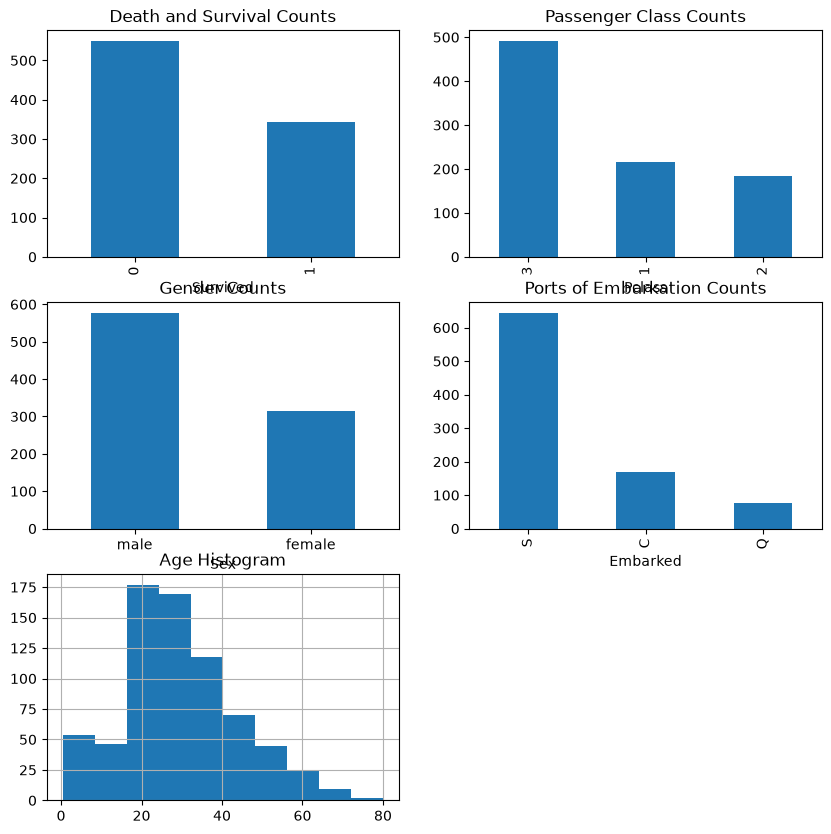

In [52]:
fig = plt.figure(figsize=fizsize_with_subplots) 
fig_dims = (3, 2)

plt.subplot2grid(fig_dims, (0, 0))
df_train['Survived'].value_counts().plot(kind='bar', title='Death and Survival Counts')

plt.subplot2grid(fig_dims, (0, 1))
df_train['Pclass'].value_counts().plot(kind='bar',   title='Passenger Class Counts')

plt.subplot2grid(fig_dims, (1, 0))
df_train['Sex'].value_counts().plot(kind='bar', title='Gender Counts')
plt.xticks(rotation=0)

plt.subplot2grid(fig_dims, (1, 1))
df_train['Embarked'].value_counts().plot(kind='bar', title='Ports of Embarkation Counts')

plt.subplot2grid(fig_dims, (2, 0))
df_train['Age'].hist()
plt.title('Age Histogram')

In [53]:
pclass_xt = pd.crosstab(df_train['Pclass'], df_train['Survived'])
pclass_xt

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_12828\505912541.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pclass_xt_pct = pclass_xt.div(pclass_xt.sum(1).astype(float), axis=0)


Text(0, 0.5, 'Survival Rate')

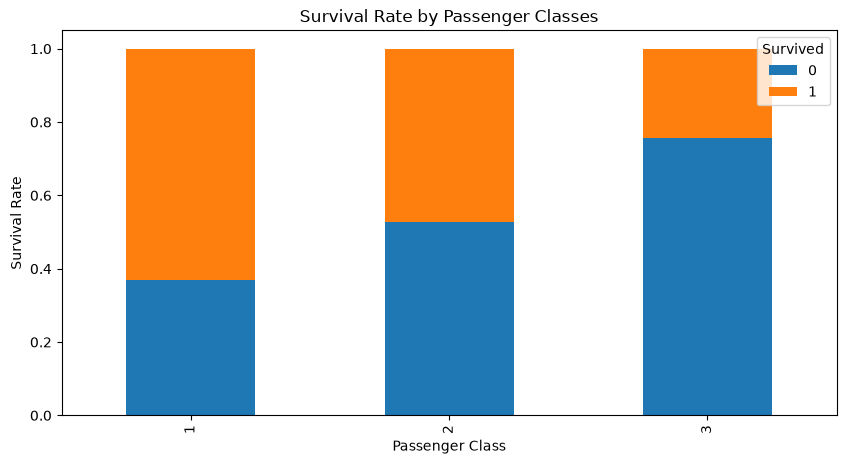

In [54]:
pclass_xt_pct = pclass_xt.div(pclass_xt.sum(1).astype(float), axis=0)

pclass_xt_pct.plot(kind='bar', 
                   stacked=True, 
                   title='Survival Rate by Passenger Classes')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

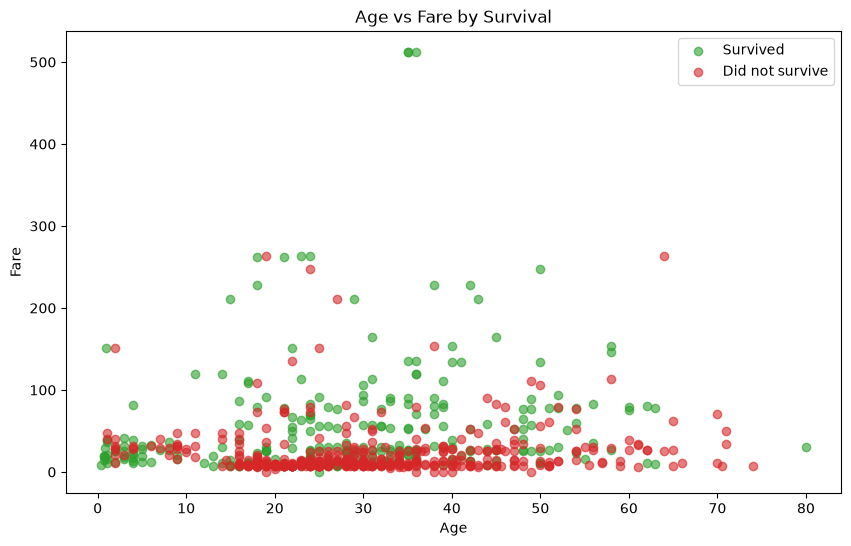

In [55]:
survived = df_train['Survived'] == 1

plt.figure(figsize=(10, 6))
plt.scatter(df_train.loc[survived, 'Age'], df_train.loc[survived, 'Fare'],
            c='tab:green', label='Survived', alpha=0.6)
plt.scatter(df_train.loc[~survived, 'Age'], df_train.loc[~survived, 'Fare'],
            c='tab:red', label='Did not survive', alpha=0.6)
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Age vs Fare by Survival')
plt.legend()
plt.show()

In [56]:
sexes = sorted(df_train['Sex'].unique())
genders_mapping = dict(zip(sexes, range(0, len(sexes) + 1)))
genders_mapping

{'female': 0, 'male': 1}

In [57]:
df_train['Sex_Val'] = df_train['Sex'].map(genders_mapping).astype(int)
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Val
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1


C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_12828\487977922.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sex_val_xt_pct = sex_val_xt.div(sex_val_xt.sum(1).astype(float), axis=0)


<Axes: title={'center': 'Survivial Rate by Gender'}, xlabel='Sex_Val'>

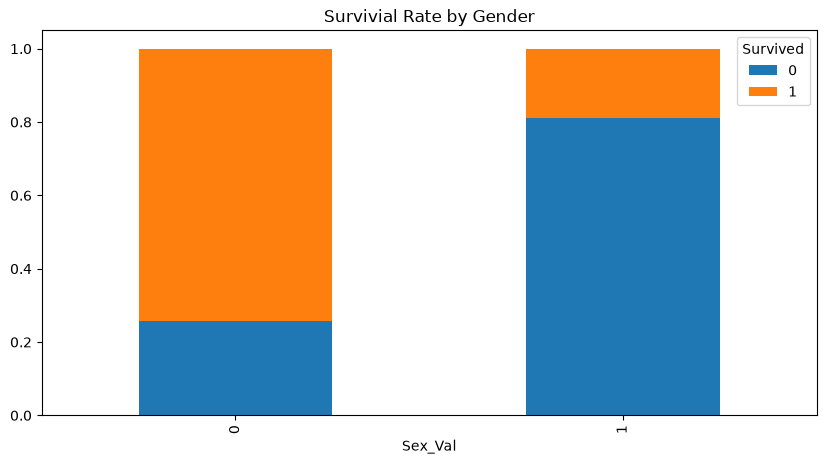

In [58]:
sex_val_xt = pd.crosstab(df_train['Sex_Val'], df_train['Survived'])
sex_val_xt_pct = sex_val_xt.div(sex_val_xt.sum(1).astype(float), axis=0)
sex_val_xt_pct.plot(kind='bar', stacked=True, title='Survivial Rate by Gender')

In [59]:
passenger_classes = sorted(df_train['Pclass'].unique())

for p_class in passenger_classes:
    print ('M: ', p_class, len(df_train[(df_train['Sex'] == 'male') & 
                             (df_train['Pclass'] == p_class)]))
    print ('F: ', p_class, len(df_train[(df_train['Sex'] == 'female') & 
                             (df_train['Pclass'] == p_class)]))

M:  1 122
F:  1 94
M:  2 108
F:  2 76
M:  3 347
F:  3 144


C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_12828\2512673684.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  females_xt_pct = females_xt.div(females_xt.sum(1).astype(float), axis=0)
C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_12828\2512673684.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  males_xt_pct = males_xt.div(males_xt.sum(1).astype(float), axis=0)


Text(0, 0.5, 'Survival Rate')

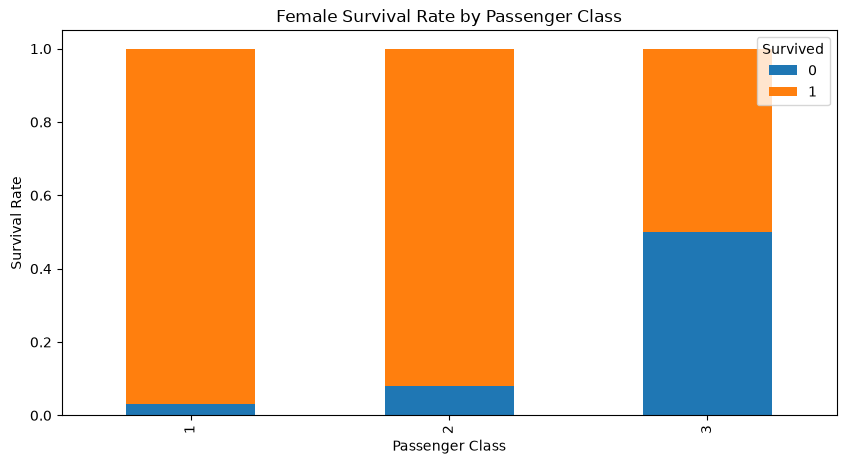

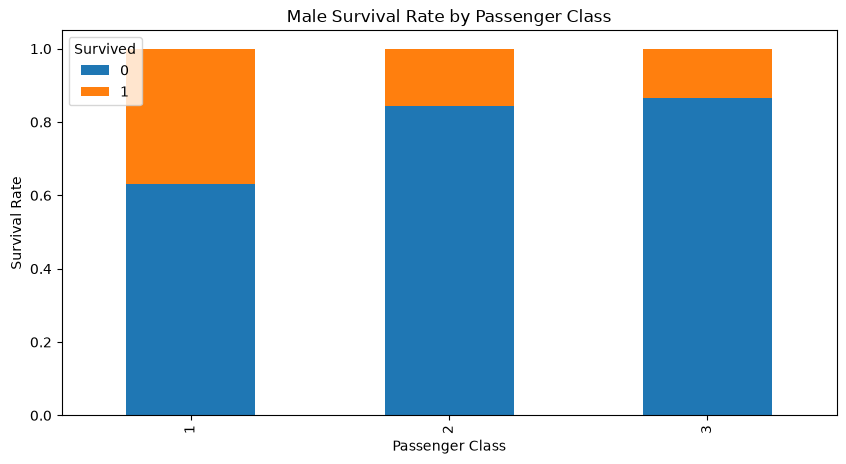

In [60]:
females_df = df_train[df_train['Sex'] == 'female']
females_xt = pd.crosstab(females_df['Pclass'], df_train['Survived'])
females_xt_pct = females_xt.div(females_xt.sum(1).astype(float), axis=0)
females_xt_pct.plot(kind='bar', 
                    stacked=True, 
                    title='Female Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

# Plot survival rate by Pclass
males_df = df_train[df_train['Sex'] == 'male']
males_xt = pd.crosstab(males_df['Pclass'], df_train['Survived'])
males_xt_pct = males_xt.div(males_xt.sum(1).astype(float), axis=0)
males_xt_pct.plot(kind='bar', 
                  stacked=True, 
                  title='Male Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

In [61]:
df_train[df_train['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Val
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN,0
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN,0


In [62]:
embarked_locs = sorted(df_train['Embarked'].dropna().unique())

embarked_locs_mapping = dict(zip(embarked_locs, range(len(embarked_locs))))
embarked_locs_mapping



{'C': 0, 'Q': 1, 'S': 2}

In [63]:
df_train['Embarked_Val'] = df_train['Embarked'].map(embarked_locs_mapping)
df_train['Embarked_Val'] = df_train['Embarked_Val'].fillna(-1).astype(int)  # -1 = unknown/missing
df_train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Val,Embarked_Val
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,2


In [64]:
df_train.loc[df_train['Embarked_Val'] == -1, 'Embarked_Val'] = embarked_locs_mapping['S']

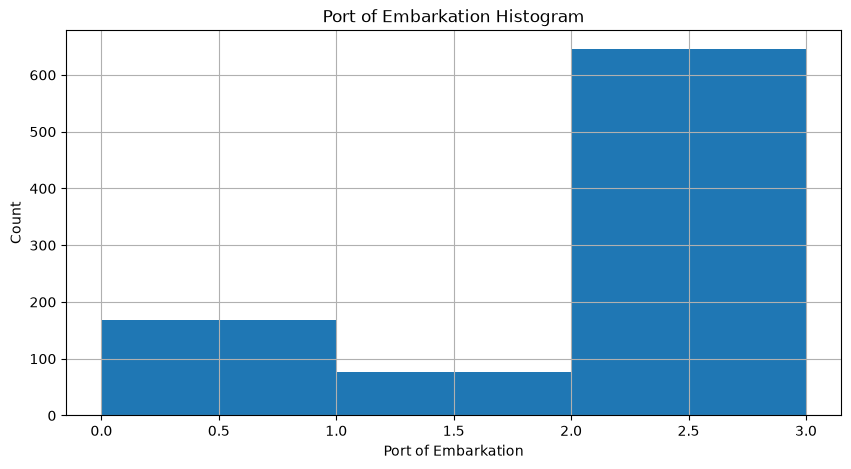

In [65]:
df_train['Embarked_Val'].hist(bins=len(embarked_locs), range=(0, 3))
plt.title('Port of Embarkation Histogram')
plt.xlabel('Port of Embarkation')
plt.ylabel('Count')
plt.show()

In [66]:
embarked_locs = sorted(df_train['Embarked_Val'].unique())
embarked_locs

[np.int64(0), np.int64(1), np.int64(2)]

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_12828\571254864.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  embarked_val_xt.div(embarked_val_xt.sum(1).astype(float), axis=0)


Text(0, 0.5, 'Survival Rate')

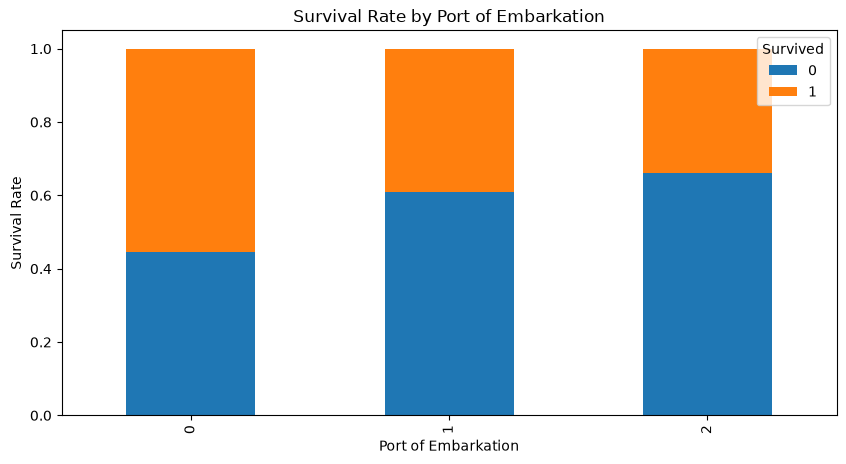

In [67]:
embarked_val_xt = pd.crosstab(df_train['Embarked_Val'], df_train['Survived'])
embarked_val_xt_pct = \
    embarked_val_xt.div(embarked_val_xt.sum(1).astype(float), axis=0)
embarked_val_xt_pct.plot(kind='bar', stacked=True)
plt.title('Survival Rate by Port of Embarkation')
plt.xlabel('Port of Embarkation')
plt.ylabel('Survival Rate')

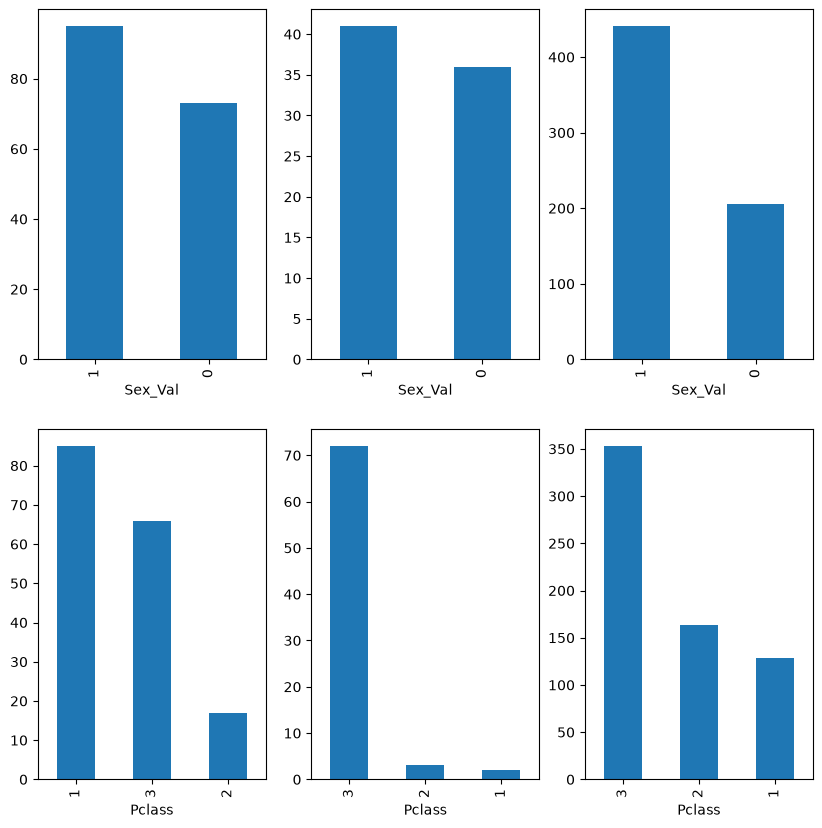

In [68]:
fig = plt.figure(figsize=fizsize_with_subplots) 

rows = 2
cols = 3
col_names = ('Sex_Val', 'Pclass')

for portIdx in embarked_locs:
    for colIdx in range(0, len(col_names)):
        plt.subplot2grid((rows, cols), (colIdx, portIdx))
        df_train[df_train['Embarked_Val'] == portIdx][col_names[colIdx]] \
            .value_counts().plot(kind='bar')


In [69]:
df_train = pd.concat([df_train, pd.get_dummies(df_train['Embarked_Val'], prefix='Embarked_Val', dtype=int)], axis=1)

In [70]:
df_train[df_train['Age'].isnull()][['Sex', 'Pclass', 'Age']].head()

,Sex,Pclass,Age
5,male,3,NaN
17,male,2,NaN
19,female,3,NaN
26,male,3,NaN
28,female,3,NaN


In [71]:
df_train['AgeFill'] = df_train.groupby(['Sex_Val', 'Pclass'])['Age'] \
    .transform(lambda x: x.fillna(x.median()))


In [72]:
len(df_train[df_train['AgeFill'].isnull()])

0

Text(0, 0.5, 'Age')

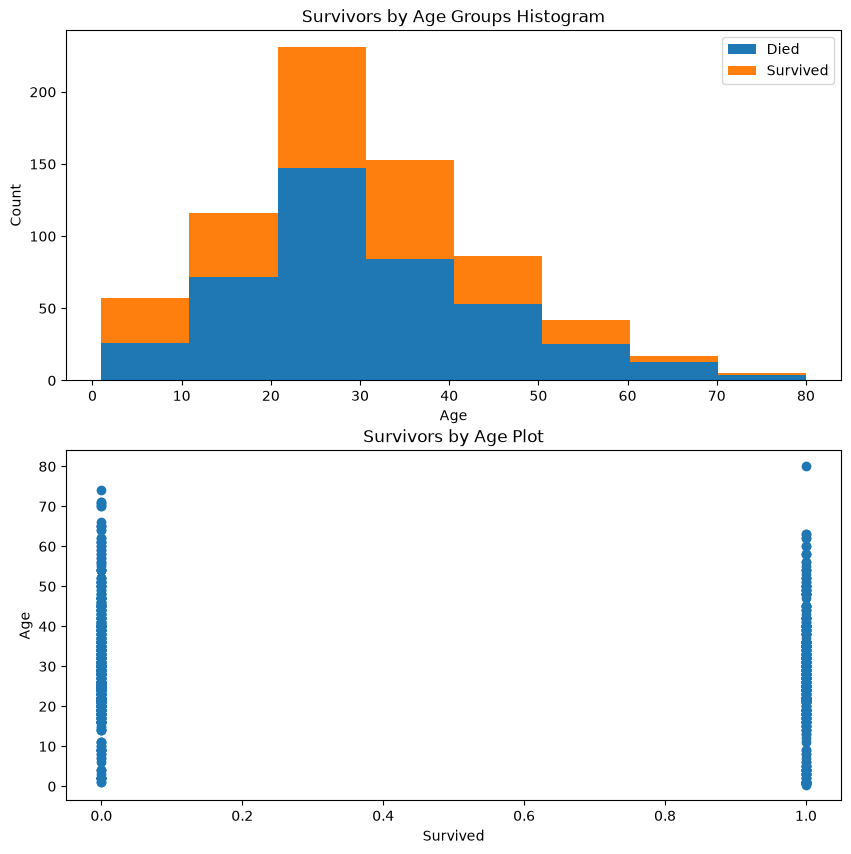

In [73]:
fig, axes = plt.subplots(2, 1, figsize=fizsize_with_subplots)

df1 = df_train[df_train['Survived'] == 0]['Age']
df2 = df_train[df_train['Survived'] == 1]['Age']
max_age = max(df_train['AgeFill'])

axes[0].hist([df1, df2], 
             bins=int(max_age // bin_size), 
             range=(1, max_age), 
             stacked=True)

axes[0].legend(('Died', 'Survived'), loc='best')
axes[0].set_title('Survivors by Age Groups Histogram')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

axes[1].scatter(df_train['Survived'], df_train['AgeFill'])
axes[1].set_title('Survivors by Age Plot')
axes[1].set_xlabel('Survived')
axes[1].set_ylabel('Age')

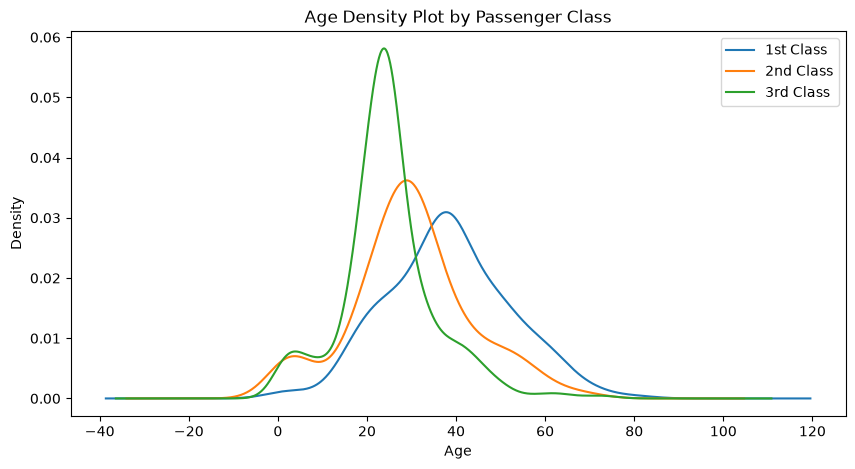

In [74]:
for pclass in passenger_classes:
    df_train.AgeFill[df_train.Pclass == pclass].plot(kind='kde')
plt.title('Age Density Plot by Passenger Class')
plt.xlabel('Age')
plt.legend(('1st Class', '2nd Class', '3rd Class'), loc='best')

<Axes: >

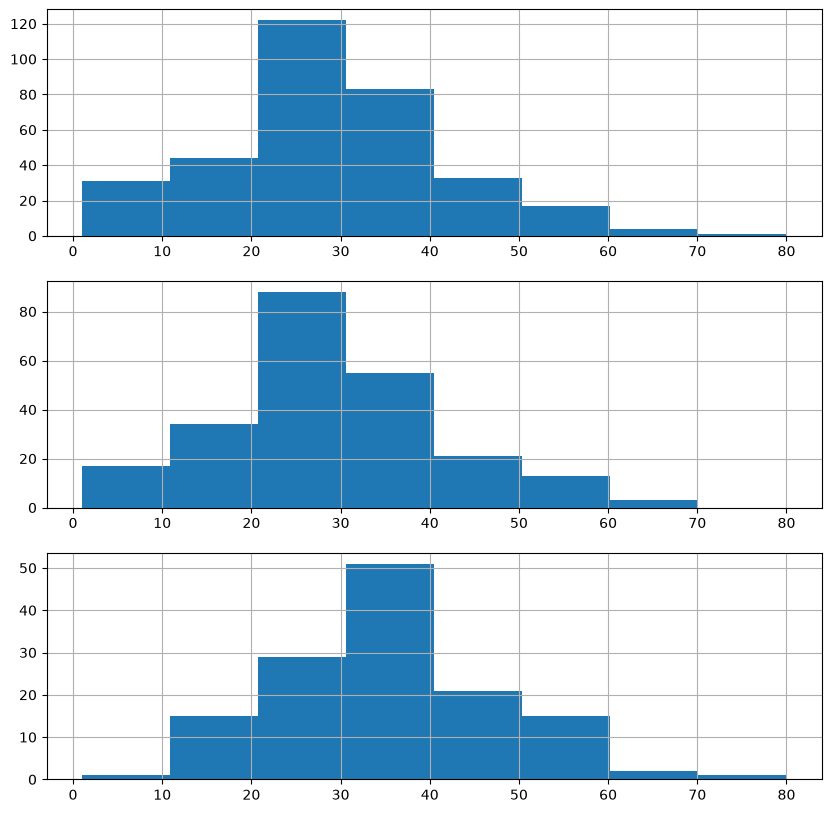

In [75]:
fig = plt.figure(figsize=fizsize_with_subplots) 
fig_dims = (3, 1)

plt.subplot2grid(fig_dims, (0, 0))
survived_df = df_train[df_train['Survived'] == 1]
survived_df['AgeFill'].hist(bins=int(max_age // bin_size), range=(1, max_age))

plt.subplot2grid(fig_dims, (1, 0))
females_df = df_train[(df_train['Sex_Val'] == 0) & (df_train['Survived'] == 1)]
females_df['AgeFill'].hist(bins=int(max_age // bin_size), range=(1, max_age))

plt.subplot2grid(fig_dims, (2, 0))
class1_df = df_train[(df_train['Pclass'] == 1) & (df_train['Survived'] == 1)]
class1_df['AgeFill'].hist(bins=int(max_age // bin_size), range=(1, max_age))


In [76]:
df_train['FamilySize'] = df_train['SibSp'] + df_train['Parch']
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Val,Embarked_Val,Embarked_Val_0,Embarked_Val_1,Embarked_Val_2,AgeFill,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1,2,0,0,1,22.0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,0,1,0,0,38.0,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,2,0,0,1,26.0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,2,0,0,1,35.0,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,2,0,0,1,35.0,0


Text(0.5, 1.0, 'Family Size Histogram')

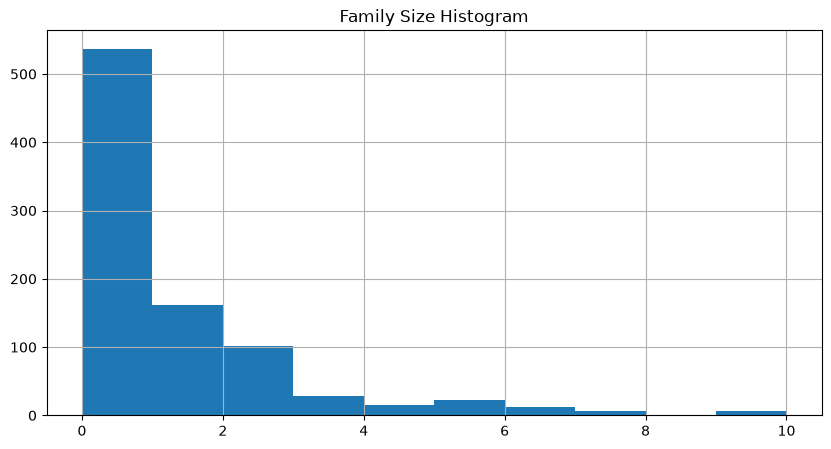

In [77]:
df_train['FamilySize'].hist()
plt.title('Family Size Histogram')

Text(0.5, 1.0, 'Survivors by Family Size')

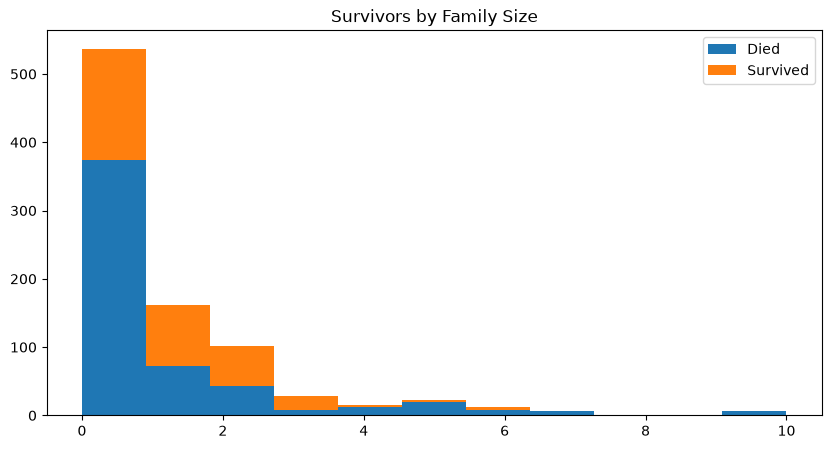

In [78]:
family_sizes = sorted(df_train['FamilySize'].unique())
family_size_max = max(family_sizes)

df1 = df_train[df_train['Survived'] == 0]['FamilySize']
df2 = df_train[df_train['Survived'] == 1]['FamilySize']
plt.hist([df1, df2], 
         bins=family_size_max + 1, 
         range=(0, family_size_max), 
         stacked=True)
plt.legend(('Died', 'Survived'), loc='best')
plt.title('Survivors by Family Size')

In [79]:
df_train.dtypes[df_train.dtypes.map(lambda x: x == 'object')]

Series([], dtype: object)

In [80]:
df_train = df_train.drop(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], axis=1, errors='ignore')

In [81]:
df_train = df_train.drop(['Age', 'SibSp', 'Parch', 'PassengerId', 'Embarked_Val'], axis=1, errors='ignore')
df_train.dtypes

Survived            int64
Pclass              int64
Fare              float64
Sex_Val             int64
Embarked_Val_0      int64
Embarked_Val_1      int64
Embarked_Val_2      int64
AgeFill           float64
FamilySize          int64
dtype: object

In [82]:
train_data = df_train.values
train_data

array([[ 0.    ,  3.    ,  7.25  , ...,  1.    , 22.    ,  1.    ],
       [ 1.    ,  1.    , 71.2833, ...,  0.    , 38.    ,  1.    ],
       [ 1.    ,  3.    ,  7.925 , ...,  1.    , 26.    ,  0.    ],
       ...,
       [ 0.    ,  3.    , 23.45  , ...,  1.    , 21.5   ,  3.    ],
       [ 1.    ,  1.    , 30.    , ...,  0.    , 26.    ,  0.    ],
       [ 0.    ,  3.    ,  7.75  , ...,  0.    , 32.    ,  0.    ]],
      shape=(891, 9))

In [83]:
def clean_data(df, drop_passenger_id):
    

    sexes = sorted(df['Sex'].unique())
    
    genders_mapping = dict(zip(sexes, range(0, len(sexes) + 1)))

    df['Sex_Val'] = df['Sex'].map(genders_mapping).astype(int)
    
    embarked_locs = sorted(df['Embarked'].dropna().unique())

    embarked_locs_mapping = dict(zip(embarked_locs, 
                                     range(0, len(embarked_locs))))

    df['Embarked_Val'] = df['Embarked'].map(embarked_locs_mapping)
    df['Embarked_Val'] = df['Embarked_Val'].fillna(embarked_locs_mapping['S']).astype(int)

    df = pd.concat([df, pd.get_dummies(df['Embarked_Val'], prefix='Embarked_Val', dtype=int)], axis=1)
    
    if df['Fare'].isnull().any():
        avg_fare = df['Fare'].mean()
        df['Fare'] = df['Fare'].fillna(avg_fare)
    
    df['AgeFill'] = df.groupby(['Sex_Val', 'Pclass'])['Age'] \
                        .transform(lambda x: x.fillna(x.median()))
            
    df['FamilySize'] = df['SibSp'] + df['Parch']
    
    df = df.drop(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked', 'Embarked_Val'], axis=1, errors='ignore')
    
    df = df.drop(['Age', 'SibSp', 'Parch'], axis=1)
    
    if drop_passenger_id:
        df = df.drop(['PassengerId'], axis=1)
    
    return df

In [84]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=100)

In [85]:
train_features = train_data[:, 1:]

train_target = train_data[:, 0]

clf = clf.fit(train_features, train_target)
score = clf.score(train_features, train_target)

"Mean accurancy of Random Forest: {0}".format(score)

'Mean accurancy of Random Forest: 0.9809203142536476'

In [86]:
df_test = pd.read_csv("titanic.csv")
df_test.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [87]:
df_test = clean_data(df_test, drop_passenger_id=False)
test_data = df_test.values

In [90]:
feature_cols = df_train.columns.drop('Survived')
test_x = df_test[feature_cols].values
test_y = clf.predict(test_x)

In [92]:
df_test['Survived'] = test_y.astype(int)
df_test[['PassengerId', 'Survived']] \
    .to_csv('titanic/results-rf.csv', index=False)


In [94]:
from sklearn import metrics
from sklearn.model_selection import train_test_split

train_x, test_x, train_y, test_y = train_test_split(train_features, 
                                                    train_target, 
                                                    test_size=0.20, 
                                                    random_state=0)
print (train_features.shape, train_target.shape)
print (train_x.shape, train_y.shape)
print (test_x.shape, test_y.shape)


(891, 8) (891,)
(712, 8) (712,)
(179, 8) (179,)


In [95]:
clf = clf.fit(train_x, train_y)
predict_y = clf.predict(test_x)
print("Accuracy = %.2f" % metrics.accuracy_score(test_y, predict_y))


Accuracy = 0.85


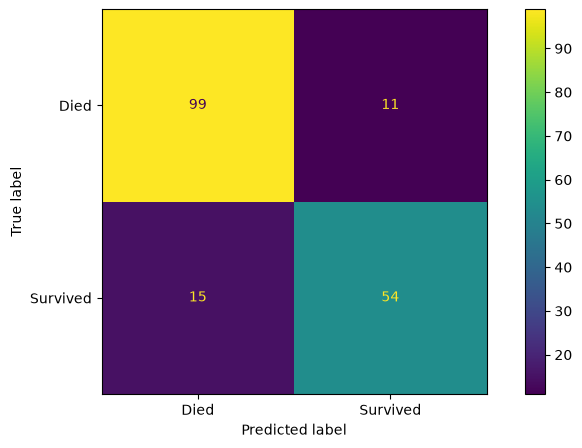

In [98]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(test_y, predict_y,
                                        display_labels=['Died', 'Survived'])
plt.show()


In [99]:
model_score = clf.score(test_x, test_y)
print ("Model Score %.2f \n" % (model_score))

confusion_matrix = metrics.confusion_matrix(test_y, predict_y)
print ("Confusion Matrix ", confusion_matrix)

print ("          Predicted")
print ("         |  0  |  1  |")
print ("         |-----|-----|")
print ("       0 | %3d | %3d |" % (confusion_matrix[0, 0],
                                   confusion_matrix[0, 1]))
print ("Actual   |-----|-----|")
print ("       1 | %3d | %3d |" % (confusion_matrix[1, 0],
                                   confusion_matrix[1, 1]))
print ("         |-----|-----|")

Model Score 0.85 

Confusion Matrix  [[99 11]
 [15 54]]
          Predicted
         |  0  |  1  |
         |-----|-----|
       0 |  99 |  11 |
Actual   |-----|-----|
       1 |  15 |  54 |
         |-----|-----|


In [100]:
from sklearn.metrics import classification_report
print(classification_report(test_y, 
                            predict_y, 
                            target_names=['Not Survived', 'Survived']))

              precision    recall  f1-score   support

Not Survived       0.87      0.90      0.88       110
    Survived       0.83      0.78      0.81        69

    accuracy                           0.85       179
   macro avg       0.85      0.84      0.84       179
weighted avg       0.85      0.85      0.85       179

